# 采购支出与供应商绩效分析

**项目目标**：从采购支出、价格竞争力、交付绩效三个维度评估供应商，识别议价机会和交付风险，并建立供应商评分卡，为分级管理提供依据。

- **数据来源**：USAID Supply Chain Shipment Pricing Data（SCMS Delivery History Dataset，CC BY-ND 4.0），共 10,324 条采购订单记录，时间跨度 2006–2015 年
- **业务背景**：美国政府资助的 SCMS 项目为非洲、亚洲等地区采购艾滋病药物和检测试剂
- **使用工具**：Python（pandas、matplotlib）

## 1. 数据读取与体检

In [1]:
# 导入 pandas，简称 pd
import pandas as pd

# 显示所有列，不要用 ... 省略（这份数据有 33 列）
pd.set_option("display.max_columns", None)

# 读取 CSV 文件，存进变量 df；df 是原始数据，后面清洗时会先复制一份，df 本身不改动
# encoding="latin-1"：这份文件不是 UTF-8 编码，用 latin-1 编码规则来读，才能识别里面的特殊字符
df = pd.read_csv("data/supply_chain_shipment.csv", encoding="latin-1")

# 打印 (行数, 列数)
print(df.shape)

# 列出每一列的名字、非空数量、数据类型
df.info()

(10324, 33)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10324 entries, 0 to 10323
Data columns (total 33 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   ID                            10324 non-null  int64  
 1   Project Code                  10324 non-null  object 
 2   PQ #                          10324 non-null  object 
 3   PO / SO #                     10324 non-null  object 
 4   ASN/DN #                      10324 non-null  object 
 5   Country                       10324 non-null  object 
 6   Managed By                    10324 non-null  object 
 7   Fulfill Via                   10324 non-null  object 
 8   Vendor INCO Term              10324 non-null  object 
 9   Shipment Mode                 9964 non-null   object 
 10  PQ First Sent to Client Date  10324 non-null  object 
 11  PO Sent to Vendor Date        10324 non-null  object 
 12  Scheduled Delivery Date       10324 non-null  ob

In [2]:
# 显示前 5 行；放在格子最后一行，Jupyter 会自动显示成表格
df.head()

,ID,Project Code,PQ #,PO / SO #,ASN/DN #,Country,Managed By,Fulfill Via,Vendor INCO Term,Shipment Mode,PQ First Sent to Client Date,PO Sent to Vendor Date,Scheduled Delivery Date,Delivered to Client Date,Delivery Recorded Date,Product Group,Sub Classification,Vendor,Item Description,Molecule/Test Type,Brand,Dosage,Dosage Form,Unit of Measure (Per Pack),Line Item Quantity,Line Item Value,Pack Price,Unit Price,Manufacturing Site,First Line Designation,Weight (Kilograms),Freight Cost (USD),Line Item Insurance (USD)
0,1,100-CI-T01,Pre-PQ Process,SCMS-4,ASN-8,Côte d'Ivoire,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,2-Jun-06,2-Jun-06,2-Jun-06,HRDT,HIV test,RANBAXY Fine Chemicals LTD.,"HIV, Reveal G3 Rapid HIV-1 Antibody Test, 30 T...","HIV, Reveal G3 Rapid HIV-1 Antibody Test",Reveal,NaN,Test kit,30,19,551.0,29.00,0.97,Ranbaxy Fine Chemicals LTD,Yes,13,780.34,NaN
1,3,108-VN-T01,Pre-PQ Process,SCMS-13,ASN-85,Vietnam,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,14-Nov-06,14-Nov-06,14-Nov-06,ARV,Pediatric,Aurobindo Pharma Limited,"Nevirapine 10mg/ml, oral suspension, Bottle, 2...",Nevirapine,Generic,10mg/ml,Oral suspension,240,1000,6200.0,6.20,0.03,"Aurobindo Unit III, India",Yes,358,4521.5,NaN
2,4,100-CI-T01,Pre-PQ Process,SCMS-20,ASN-14,Côte d'Ivoire,PMO - US,Direct Drop,FCA,Air,Pre-PQ Process,Date Not Captured,27-Aug-06,27-Aug-06,27-Aug-06,HRDT,HIV test,Abbott GmbH & Co. KG,"HIV 1/2, Determine Complete HIV Kit, 100 Tests","HIV 1/2, Determine Complete HIV Kit",Determine,NaN,Test kit,100,500,40000.0,80.00,0.80,ABBVIE GmbH & Co.KG Wiesbaden,Yes,171,1653.78,NaN
3,15,108-VN-T01,Pre-PQ Process,SCMS-78,ASN-50,Vietnam,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,1-Sep-06,1-Sep-06,1-Sep-06,ARV,Adult,SUN PHARMACEUTICAL INDUSTRIES LTD (RANBAXY LAB...,"Lamivudine 150mg, tablets, 60 Tabs",Lamivudine,Generic,150mg,Tablet,60,31920,127360.8,3.99,0.07,"Ranbaxy, Paonta Shahib, India",Yes,1855,16007.06,NaN
4,16,108-VN-T01,Pre-PQ Process,SCMS-81,ASN-55,Vietnam,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,11-Aug-06,11-Aug-06,11-Aug-06,ARV,Adult,Aurobindo Pharma Limited,"Stavudine 30mg, capsules, 60 Caps",Stavudine,Generic,30mg,Capsule,60,38000,121600.0,3.20,0.05,"Aurobindo Unit III, India",Yes,7590,45450.08,NaN


In [3]:
# 1. 供应商列：出现次数最多的前 10 个供应商
#    value_counts() 统计每个值出现了几次，head(10) 只看前 10 个
print("【Vendor 前 10】")
print(df["Vendor"].value_counts().head(10))

# 2. 运费列：出现次数最多的前 10 种写法，检查有哪些不是数字的文字
print("\n【Freight Cost (USD) 前 10】")
print(df["Freight Cost (USD)"].value_counts().head(10))

# 3. 重量列：同样检查有没有混入文字
print("\n【Weight (Kilograms) 前 10】")
print(df["Weight (Kilograms)"].value_counts().head(10))

# 4. 计划交付日期：看日期的写法格式
print("\n【Scheduled Delivery Date 前 5】")
print(df["Scheduled Delivery Date"].value_counts().head(5))

# 5. 下单日期：检查有没有混入文字
print("\n【PO Sent to Vendor Date 前 5】")
print(df["PO Sent to Vendor Date"].value_counts().head(5))

【Vendor 前 10】
Vendor
SCMS from RDC                                            5404
Orgenics, Ltd                                             754
S. BUYS WHOLESALER                                        715
Aurobindo Pharma Limited                                  668
Trinity Biotech, Plc                                      356
ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV)           347
PHARMACY DIRECT                                           326
MYLAN LABORATORIES LTD (FORMERLY MATRIX LABORATORIES)     317
HETERO LABS LIMITED                                       277
CIPLA LIMITED                                             175
Name: count, dtype: int64

【Freight Cost (USD) 前 10】
Freight Cost (USD)
Freight Included in Commodity Cost    1442
Invoiced Separately                    239
9736.1                                  36
6147.18                                 27
See DN-304 (ID#:10589)                  16
7445.8                                  16
13398.06                     

In [4]:
# 1. 订单的发货方式：Direct Drop（供应商直接发货）和 From RDC（从配送中心发货）各有多少行
print("【Fulfill Via 发货方式】")
print(df["Fulfill Via"].value_counts())

# 2. 交叉核对：发货方式 和 供应商是否为 "SCMS from RDC" 是否一一对应
#    pd.crosstab 做一张交叉计数表：行是发货方式，列是 True/False（是不是 SCMS from RDC）
print("\n【交叉核对：发货方式 × 是否 SCMS from RDC】")
print(pd.crosstab(df["Fulfill Via"], df["Vendor"] == "SCMS from RDC"))

# 3. 实际到货日期：看看里面混了哪些文字
print("\n【Delivered to Client Date 前 5】")
print(df["Delivered to Client Date"].value_counts().head(5))

# 4. 完全重复的行有多少
print("\n完全重复的行数：", df.duplicated().sum())

# 5. 数量或金额小于等于 0 的行有多少
print("数量 <= 0 的行数：", (df["Line Item Quantity"] <= 0).sum())
print("金额 <= 0 的行数：", (df["Line Item Value"] <= 0).sum())

# 6. 运费列：把文字分成几大类，看每类有多少行
#    str.startswith("See") 判断是否以 "See" 开头（合并运输、运费记在别的行）
freight = df["Freight Cost (USD)"].astype(str)
print("\n【运费列分类】")
print("以 See 开头（记在别的行）：", freight.str.startswith("See").sum())
print("含在货款里：", (freight == "Freight Included in Commodity Cost").sum())
print("另外开票：", (freight == "Invoiced Separately").sum())

# pd.to_numeric(..., errors="coerce")：尝试把文字转成数字，转不了的变成空值 NaN
# notna().sum() 数一数能成功转成数字的有多少行
print("能转成数字的：", pd.to_numeric(df["Freight Cost (USD)"], errors="coerce").notna().sum())

【Fulfill Via 发货方式】
Fulfill Via
From RDC       5404
Direct Drop    4920
Name: count, dtype: int64

【交叉核对：发货方式 × 是否 SCMS from RDC】
Vendor       False  True 
Fulfill Via              
Direct Drop   4920      0
From RDC         0   5404

【Delivered to Client Date 前 5】
Delivered to Client Date
29-Aug-14    74
27-Aug-14    66
14-Feb-12    60
28-Jun-10    60
16-Apr-13    59
Name: count, dtype: int64

完全重复的行数： 0
数量 <= 0 的行数： 0
金额 <= 0 的行数： 17

【运费列分类】
以 See 开头（记在别的行）： 2445
含在货款里： 1442
另外开票： 239
能转成数字的： 6198


## 2. 数据清洗

In [5]:
# ===== 2. 数据清洗 =====

# 复制一份原始数据来清洗，df 保持原样不动，万一出错可以从头再来
df_clean = df.copy()
print("清洗前行数：", len(df_clean))

# --- 1. 删除金额 <= 0 的记录 ---
# 先把这 17 行挑出来看一眼：是谁的订单、什么商品、数量和单价是多少
zero_value = df_clean[df_clean["Line Item Value"] <= 0]
print("\n【金额 <= 0 的记录】")
print(zero_value[["ID", "Vendor", "Fulfill Via", "Product Group",
                  "Line Item Quantity", "Line Item Value", "Unit Price"]])

before = len(df_clean)                                  # 记下删除前的行数
df_clean = df_clean[df_clean["Line Item Value"] > 0]    # 只保留金额大于 0 的行
print("\n1. 删除金额 <= 0：", before - len(df_clean), "行")

# --- 2. 处理运费列：拆成“运费金额”和“运费类型”两列 ---
# 原来的运费列保持不动，新建两列，方便后面分析时选择

# 先把运费列转成文字，方便判断开头和内容
freight_text = df_clean["Freight Cost (USD)"].astype(str)

# 新列 Freight_Num：能转成数字的变成数字，文字一律变成空值 NaN
# errors="coerce" 的意思是“转不了的不要报错，直接变成空值”
df_clean["Freight_Num"] = pd.to_numeric(df_clean["Freight Cost (USD)"], errors="coerce")

# 新列 Freight_Type：先全部填成 "Numeric"（有运费金额），再按文字内容改写
# .loc[条件, "列名"] = 值：只在满足条件的行里，把这一列改成指定的值
df_clean["Freight_Type"] = "Numeric"
df_clean.loc[freight_text == "Freight Included in Commodity Cost", "Freight_Type"] = "Included in Commodity"
df_clean.loc[freight_text == "Invoiced Separately", "Freight_Type"] = "Invoiced Separately"
df_clean.loc[freight_text.str.startswith("See"), "Freight_Type"] = "See Other Shipment"

print("\n2. 运费类型分布：")
print(df_clean["Freight_Type"].value_counts())

# --- 3. 日期列转成真正的日期格式 ---
# format 告诉 pandas 日期是怎么写的：
#   "%d-%b-%y" 对应 29-Aug-14：%d 日，%b 英文月份缩写，%y 两位年份
#   "%m/%d/%Y" 对应 8/27/2014：%m 月，%d 日，%Y 四位年份
# errors="coerce"：像 "N/A - From RDC" 这样的文字转不了，就变成空日期 NaT
df_clean["Scheduled_Date"] = pd.to_datetime(df_clean["Scheduled Delivery Date"],
                                            format="%d-%b-%y", errors="coerce")
df_clean["Delivered_Date"] = pd.to_datetime(df_clean["Delivered to Client Date"],
                                            format="%d-%b-%y", errors="coerce")
df_clean["PO_Sent_Date"] = pd.to_datetime(df_clean["PO Sent to Vendor Date"],
                                          format="%m/%d/%Y", errors="coerce")

# 数一数每个日期列有多少行没能转换成功（isna() 把空日期标成 True，sum() 数 True 的个数）
print("\n3. 日期转换失败的行数：")
print("计划到货日：", df_clean["Scheduled_Date"].isna().sum())
print("实际到货日：", df_clean["Delivered_Date"].isna().sum())
print("下单日：", df_clean["PO_Sent_Date"].isna().sum())

# 看一下日期范围，确认转换出来的年份合理（min 最早，max 最晚）
print("\n实际到货日范围：", df_clean["Delivered_Date"].min(), "至", df_clean["Delivered_Date"].max())

# --- 4. 拆出供应商直接发货的订单，用于后面所有“按供应商”的分析 ---
# From RDC 的订单供应商一律是 "SCMS from RDC"，看不到真实供应商，所以不放进供应商分析
df_direct = df_clean[df_clean["Fulfill Via"] == "Direct Drop"].copy()

print("\n4. 清洗后总行数：", len(df_clean))
print("   其中供应商直接发货（用于供应商分析）：", len(df_direct), "行")
print("   涉及的供应商数量：", df_direct["Vendor"].nunique())

清洗前行数： 10324

【金额 <= 0 的记录】
          ID                      Vendor  Fulfill Via Product Group  \
1284   10910               SCMS from RDC     From RDC           ARV   
2398   12522               SCMS from RDC     From RDC           ARV   
2750   14079  Standard Diagnostics, Inc.  Direct Drop          HRDT   
2915   17135  Standard Diagnostics, Inc.  Direct Drop          HRDT   
3023   19405  Standard Diagnostics, Inc.  Direct Drop          HRDT   
3338   24653  Standard Diagnostics, Inc.  Direct Drop          HRDT   
5128   56899  Standard Diagnostics, Inc.  Direct Drop          HRDT   
5362   61493  Standard Diagnostics, Inc.  Direct Drop          HRDT   
5628   65555  Standard Diagnostics, Inc.  Direct Drop          HRDT   
5765   67769  Standard Diagnostics, Inc.  Direct Drop          HRDT   
6057   72922  Standard Diagnostics, Inc.  Direct Drop          HRDT   
6973   82725               SCMS from RDC     From RDC           ARV   
8812   84945               SCMS from RDC     From

**清洗小结**

- 原始数据 10,324 行，无完全重复行，无数量 ≤ 0 的记录
- 删除金额为 0 的记录 17 行（数量正常但金额为 0，推断为赠送或附赠货物，不计入支出，也避免干扰价格对标）
- 运费列拆分为金额（Freight_Num）和类型（Freight_Type）两列：6,186 行有运费金额，其余为“含在货款中”“另行开票”或“与其他订单合并运输”
- 三个日期列转为日期格式；计划到货日与实际到货日完整无缺失，下单日有 5,724 行缺失（配送中心发货或未记录）
- 52% 的订单由 SCMS 区域配送中心（RDC）发货，其供应商字段统一为 “SCMS from RDC”，无法识别真实供应商。因此供应商层面的分析仅使用供应商直接发货的 4,911 行订单，涉及 72 家供应商
- 数据时间跨度为 2006 年 5 月至 2015 年 9 月

## 3. 支出分析

In [6]:
# ===== 3. 支出分析 =====

# --- 1. 总支出，以及配送中心发货 vs 供应商直接发货各占多少 ---
total_spend = df_clean["Line Item Value"].sum()                    # 全部订单的货款总额
rdc_spend = df_clean.loc[df_clean["Fulfill Via"] == "From RDC",    # 只挑配送中心发货的行
                         "Line Item Value"].sum()                  # 把它们的金额加起来
direct_spend = df_direct["Line Item Value"].sum()                  # 供应商直接发货的金额

# f"{数字:,.0f}"：数字加千分位逗号、不保留小数；f"{数字:.1%}"：转成百分数、保留 1 位小数
print(f"总支出：${total_spend:,.0f}")
print(f"配送中心发货：${rdc_spend:,.0f}（{rdc_spend / total_spend:.1%}）")
print(f"供应商直接发货：${direct_spend:,.0f}（{direct_spend / total_spend:.1%}）")

# --- 2. 按供应商汇总支出（只用直接发货的订单）---
vendor_spend = df_direct.groupby("Vendor").agg(
    TotalSpend=("Line Item Value", "sum"),   # 每家供应商的总支出
    OrderLines=("ID", "count")               # 每家供应商有多少行订单
).sort_values("TotalSpend", ascending=False).reset_index()   # 从高到低排序，再重新编行号

# 每家供应商的支出占比，以及从第一名开始的累计占比（和 ABC 项目的算法一样）
vendor_spend["SpendShare"] = vendor_spend["TotalSpend"] / vendor_spend["TotalSpend"].sum()
vendor_spend["CumShare"] = vendor_spend["SpendShare"].cumsum()

# --- 3. CR4：前 4 大供应商的支出合计占比 ---
# head(4) 取排名前 4 的供应商，把它们的占比加起来
cr4 = vendor_spend["SpendShare"].head(4).sum()
print(f"\n供应商数量：{len(vendor_spend)}")
print(f"CR4（前 4 大供应商支出占比）：{cr4:.1%}")

# 要几家供应商才能累计到 80% 的支出？
# (CumShare < 0.80).sum() 数出累计占比还没到 80% 的供应商有几家，再加上跨过 80% 的那一家
n80 = (vendor_spend["CumShare"] < 0.80).sum() + 1
print(f"累计达到 80% 支出所需的供应商数：{n80} 家（占全部供应商的 {n80 / len(vendor_spend):.1%}）")

# --- 4. 看支出前 10 的供应商 ---
# 为了好读，复制一份前 10 行，把金额取整、把占比换成百分数
top10 = vendor_spend.head(10).copy()
top10["TotalSpend"] = top10["TotalSpend"].round(0)
top10["SpendShare"] = (top10["SpendShare"] * 100).round(1)   # 单位：%
top10["CumShare"] = (top10["CumShare"] * 100).round(1)       # 单位：%
print("\n支出前 10 的供应商：")
print(top10)

# --- 5. 按品类汇总支出（用全部订单，因为品类不需要知道供应商是谁）---
category_spend = df_clean.groupby("Product Group")["Line Item Value"].sum().sort_values(ascending=False)
print("\n各品类支出占比（%）：")
print((category_spend / category_spend.sum() * 100).round(1))
# 验证：排名第 23~72 名的 50 家尾部供应商，支出合计占比多少
# iloc[22:]：按位置取第 23 行到最后一行（位置从 0 开始数，所以第 23 名的位置是 22）
print(f"\n排名后 50 家供应商的支出合计占比：{vendor_spend['SpendShare'].iloc[22:].sum():.1%}")

总支出：$1,627,584,457
配送中心发货：$1,085,372,435（66.7%）
供应商直接发货：$542,212,022（33.3%）

供应商数量：72
CR4（前 4 大供应商支出占比）：65.3%
累计达到 80% 支出所需的供应商数：7 家（占全部供应商的 9.7%）

支出前 10 的供应商：
                                              Vendor   TotalSpend  OrderLines  \
0                                      Orgenics, Ltd  147703351.0         754   
1                           Aurobindo Pharma Limited   91383711.0         668   
2  MYLAN LABORATORIES LTD (FORMERLY MATRIX LABORA...   72213666.0         317   
3                                HETERO LABS LIMITED   42881567.0         277   
4                                      CIPLA LIMITED   39658695.0         175   
5    ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV)   29448061.0         347   
6                            STRIDES ARCOLAB LIMITED   22485465.0          93   
7                               Trinity Biotech, Plc   20769341.0         356   
8                                 S. BUYS WHOLESALER    9891004.0         715   
9                         Sta

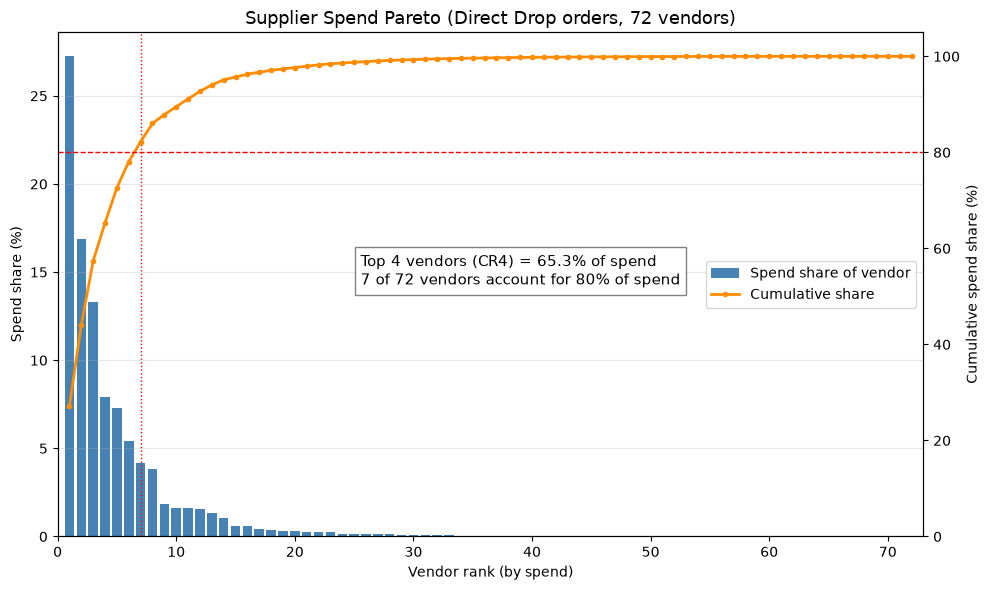

In [7]:
# ===== 供应商支出帕累托图 =====
import matplotlib.pyplot as plt   # 导入画图工具
import os                         # 导入处理文件夹的工具

# 新建 images 文件夹存放图片；已经存在也不报错
os.makedirs("images", exist_ok=True)
# 恢复 matplotlib 默认样式（白色背景、黑色文字），不受 PyCharm 深色主题影响
# 这样保存的图片放进 README 或报告里也是白底，看起来统一
plt.style.use("default")

# 横轴：供应商排名 1, 2, 3, ……, 72
# vendor_spend 已经按支出从高到低排好，行号是 0~71，加 1 变成排名
rank = vendor_spend.index + 1

# 新建画布
fig, ax = plt.subplots(figsize=(10, 6))

# 左边的纵轴：画柱子，高度是每家供应商的支出占比（乘 100 变成百分数）
ax.bar(rank, vendor_spend["SpendShare"] * 100, color="steelblue", label="Spend share of vendor")
ax.set_xlabel("Vendor rank (by spend)")
ax.set_ylabel("Spend share (%)")

# twinx()：在同一张图上再加一个“共用横轴、右边单独一套刻度”的纵轴，用来画累计占比
ax2 = ax.twinx()
ax2.plot(rank, vendor_spend["CumShare"] * 100, color="darkorange", marker="o",
         markersize=3, linewidth=2, label="Cumulative share")
ax2.set_ylabel("Cumulative spend share (%)")
ax2.set_ylim(0, 105)   # 右边纵轴固定 0~105，顶部留一点空

# 80% 的水平虚线，以及“第 n80 名”的竖直虚线
ax2.axhline(80, color="red", linestyle="--", linewidth=1)
ax.axvline(n80, color="red", linestyle=":", linewidth=1)

# 在图上写一段文字说明 CR4 和 80% 需要几家供应商
# transform=ax.transAxes：坐标按“图框比例”算，(0.35, 0.5) 表示横向 35%、纵向 50% 的位置
ax.text(0.35, 0.5,
        f"Top 4 vendors (CR4) = {cr4:.1%} of spend\n"
        f"{n80} of {len(vendor_spend)} vendors account for 80% of spend",
        transform=ax.transAxes, fontsize=11,color="black",
        bbox=dict(facecolor="white", edgecolor="gray"))   # bbox：给文字加白底灰边的框

ax.set_title("Supplier Spend Pareto (Direct Drop orders, 72 vendors)", fontsize=13)
ax.set_xlim(0, len(vendor_spend) + 1)
ax.grid(axis="y", alpha=0.3)

# 两个纵轴各有自己的图例，这里把它们合并成一个
# get_legend_handles_labels() 取出每个轴上的“图例项”，相加后统一显示
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="center right")

plt.tight_layout()
plt.savefig("images/vendor_pareto.png", dpi=150)   # 保存图片
plt.show()

**支出分析结论**

- 清洗后总采购额约 16.28 亿美元。其中 66.7% 经 SCMS 区域配送中心发货，无法识别上游供应商；供应商直接发货部分约 5.42 亿美元（33.3%），涉及 72 家供应商，是本项目供应商分析的范围
- 供应商高度集中：前 4 大供应商（CR4）占直接采购支出的 65.3%；7 家供应商（占 9.7%）贡献了 80% 的支出。第 1 名 Orgenics 一家就占 27.2%
- 订单行数与支出不成正比：S. BUYS WHOLESALER 订单行数（715）与第 1 名接近，但支出占比仅 1.8%
- 品类上，抗逆转录病毒药物（ARV）占全部支出的 86.8%，HIV 快速检测试剂（HRDT）占 13.1%，疟疾相关品类占比不足 0.1%
- 采购启示：头部供应商议价空间大，但单一供应商依赖度高（第 1 名占 27%），需要关注供应连续性风险；排名后 50 家供应商（约占供应商总数的七成）合计仅贡献 1.8% 的支出，可评估整合精简的空间

## 4. 价格对标

In [8]:
# ===== 4. 价格对标：先做两项检查 =====

# --- 检查 1：数量是按“包”还是按“片”算的？ ---
# 如果 Pack Price × Line Item Quantity ≈ Line Item Value，说明数量单位是“包”
calc_value = df_direct["Pack Price"] * df_direct["Line Item Quantity"]

# 计算两者的差距占实际金额的百分比；abs() 取绝对值，去掉正负号
diff_pct = (calc_value - df_direct["Line Item Value"]).abs() / df_direct["Line Item Value"]

# 差距小于 1% 的行有多少（允许一点四舍五入误差）
print("Pack Price × 数量 与金额一致（误差 < 1%）的行数：",
      (diff_pct < 0.01).sum(), "/", len(df_direct))

# --- 检查 2：有多少商品有多家供应商可比 ---
# 新增一列“年份”：用实际到货日期的年份（这一列没有缺失）
# .dt.year：从日期里取出年份，比如 2014-08-29 → 2014
df_direct["Year"] = df_direct["Delivered_Date"].dt.year

# 不同商品规格的数量（Item Description 里已经包含了药名、剂量、剂型和包装规格）
print("\n不同商品规格数：", df_direct["Item Description"].nunique())

# 每个商品有几家不同的供应商
vendors_per_item = df_direct.groupby("Item Description")["Vendor"].nunique()
print("有 2 家及以上供应商的商品规格数：", (vendors_per_item >= 2).sum())

# 同一个商品、同一年里有几家不同的供应商（同一年内比较价格更公平）
vendors_per_item_year = df_direct.groupby(["Item Description", "Year"])["Vendor"].nunique()
print("同一年内有 2 家及以上供应商的“商品 × 年份”组合数：", (vendors_per_item_year >= 2).sum())

# --- 看一个具体例子：支出最高的 10 个商品，各有几家供应商 ---
item_summary = df_direct.groupby("Item Description").agg(
    TotalSpend=("Line Item Value", "sum"),     # 这个商品的总支出
    Vendors=("Vendor", "nunique"),            # 有几家供应商
    MinPackPrice=("Pack Price", "min"),       # 最低每包价格
    MaxPackPrice=("Pack Price", "max")        # 最高每包价格
).sort_values("TotalSpend", ascending=False)

print("\n支出最高的 10 个商品：")
print(item_summary.head(10))

Pack Price × 数量 与金额一致（误差 < 1%）的行数： 4910 / 4911

不同商品规格数： 174
有 2 家及以上供应商的商品规格数： 84
同一年内有 2 家及以上供应商的“商品 × 年份”组合数： 199

支出最高的 10 个商品：
                                                      TotalSpend  Vendors  \
Item Description                                                            
HIV 1/2, Determine Complete HIV Kit, 100 Tests      1.342513e+08        8   
Efavirenz 600mg, tablets, 30 Tabs                   4.363712e+07        9   
Efavirenz/Lamivudine/Tenofovir Disoproxil Fumar...  4.201060e+07        4   
Tenofovir Disoproxil Fumarate 300mg, tablets, 3...  3.395228e+07        6   
Lamivudine/Nevirapine/Zidovudine 150/200/300mg,...  2.796032e+07        5   
Lopinavir/Ritonavir 200/50mg [Aluvia], tablets,...  2.701658e+07        5   
HIV 1/2, Uni-Gold HIV Kit, 20 Tests                 2.031844e+07        2   
Lamivudine 150mg, tablets, 60 Tabs                  2.000676e+07        8   
HIV 1/2, Determine HIV Kit, without Lancets, 10...  1.783594e+07        3   
Lamivudine/Tenofovir 

In [9]:
# ===== 检查异常价格 =====

# --- 1. 计算每个“商品 × 年份”的每包价格中位数，贴回每一行 ---
# transform("median")：按组算中位数，并保持原来的行数（ABC 项目里用过）
df_direct["MedianPackPrice"] = (df_direct.groupby(["Item Description", "Year"])["Pack Price"]
                                .transform("median"))

# --- 2. 异常低价：每包价格低于同商品同年份中位数的 10% ---
low_price = df_direct[df_direct["Pack Price"] < df_direct["MedianPackPrice"] * 0.1]
print("异常低价记录数：", len(low_price))
print(f"这些记录的金额合计：${low_price['Line Item Value'].sum():,.0f}")
print("\n按金额从大到小，前 15 条：")
print(low_price[["ID", "Vendor", "Item Description", "Year", "Line Item Quantity",
                 "Pack Price", "MedianPackPrice", "Line Item Value"]]
      .sort_values("Line Item Value", ascending=False).head(15))

# --- 3. 偏高的一侧：每包价格超过中位数 3 倍的记录有多少 ---
high_price = df_direct[df_direct["Pack Price"] > df_direct["MedianPackPrice"] * 3]
print("\n价格超过中位数 3 倍的记录数：", len(high_price))
print(high_price[["Vendor", "Item Description", "Year", "Pack Price", "MedianPackPrice"]].head(10))

# --- 4. 那 1 行“Pack Price × 数量 ≠ 金额”的记录是什么 ---
# diff_pct 是上一个格子（价格对标的两项检查）算出来的，它的行号和 df_direct 一一对应，可以直接用来筛选
print("\n金额对不上的记录：")
print(df_direct[diff_pct >= 0.01][["ID", "Vendor", "Item Description", "Line Item Quantity",
                                   "Pack Price", "Line Item Value"]])

异常低价记录数： 5
这些记录的金额合计：$11

按金额从大到小，前 15 条：
         ID                                             Vendor  \
924    9550                                   ASPEN PHARMACARE   
4773  50483                           Aurobindo Pharma Limited   
682    6837                                   ASPEN PHARMACARE   
3356  24990                               Trinity Biotech, Plc   
4599  47301  MYLAN LABORATORIES LTD (FORMERLY MATRIX LABORA...   

                                       Item Description  Year  \
924   Tenofovir Disoproxil Fumarate 300mg [Viread], ...  2008   
4773  Tenofovir Disoproxil Fumarate 300mg, tablets, ...  2009   
682   Tenofovir Disoproxil Fumarate 300mg [Viread], ...  2008   
3356                HIV 1/2, Uni-Gold HIV Kit, 20 Tests  2009   
4599  Lamivudine/Nevirapine/Zidovudine 30/50/60mg, d...  2015   

      Line Item Quantity  Pack Price  MedianPackPrice  Line Item Value  
924                  780        0.01            21.27             7.80  
4773                 250

In [10]:
# ===== 价格对标：计算价差率和潜在节约 =====

# --- 1. 排除 5 行异常低价，得到用于价格对标的数据 ---
price_df = df_direct[df_direct["Pack Price"] >= df_direct["MedianPackPrice"] * 0.1].copy()
print("价格对标使用的订单行数：", len(price_df))

# --- 2. 每家供应商、每个商品、每一年：汇总金额和包数，算加权平均每包价格 ---
vendor_item = price_df.groupby(["Item Description", "Year", "Vendor"]).agg(
    Spend=("Line Item Value", "sum"),        # 这家供应商这一年在这个商品上的总金额
    Qty=("Line Item Quantity", "sum"),       # 总包数
    Lines=("ID", "count")                    # 订单行数
).reset_index()

# 加权平均每包价格 = 总金额 ÷ 总包数（大订单的价格自然占更大的分量）
vendor_item["AvgPackPrice"] = vendor_item["Spend"] / vendor_item["Qty"]

# --- 3. 只保留“同一商品同一年有 2 家及以上供应商”的组 ---
# transform("count")：数每个“商品 × 年份”组里有几行；这里每行就是一家供应商，所以就是供应商数
vendor_item["VendorsInGroup"] = (vendor_item.groupby(["Item Description", "Year"])["Vendor"]
                                 .transform("count"))
comparable = vendor_item[vendor_item["VendorsInGroup"] >= 2].copy()

# --- 4. 对标价：同组里加权平均价格最低的那家 ---
comparable["BenchmarkPrice"] = (comparable.groupby(["Item Description", "Year"])["AvgPackPrice"]
                                .transform("min"))

# 价差率：比对标价贵了百分之多少（对标供应商自己是 0）
comparable["GapRate"] = (comparable["AvgPackPrice"] - comparable["BenchmarkPrice"]) / comparable["BenchmarkPrice"]

# 潜在节约：每包贵出来的钱 × 买了多少包
comparable["PotentialSaving"] = (comparable["AvgPackPrice"] - comparable["BenchmarkPrice"]) * comparable["Qty"]

# --- 5. 总体结果 ---
comparable_spend = comparable["Spend"].sum()
total_saving = comparable["PotentialSaving"].sum()
print("可比较的“商品 × 年份”组数：", comparable.groupby(["Item Description", "Year"]).ngroups)
print("涉及的商品规格数：", comparable["Item Description"].nunique())
print(f"可比较部分的支出：${comparable_spend:,.0f}（占直接采购支出的 {comparable_spend / direct_spend:.1%}）")
print(f"潜在议价空间（理论上限）：${total_saving:,.0f}（占可比较支出的 {total_saving / comparable_spend:.1%}）")

# --- 6. 价差有多大：每组的“最贵供应商比最便宜的贵多少” ---
group_gap = comparable.groupby(["Item Description", "Year"])["GapRate"].max()
print("\n组内最大价差率超过不同阈值的组数：")
for t in [0.1, 0.2, 0.5, 1.0]:
    print(f"  超过 {t:.0%}：{(group_gap > t).sum()} 组")

# --- 7. 潜在节约最大的 10 条：哪家供应商、哪个商品、哪一年 ---
top_saving = comparable.sort_values("PotentialSaving", ascending=False).head(10).copy()
top_saving["GapRate"] = (top_saving["GapRate"] * 100).round(1)          # 换成百分数
top_saving["PotentialSaving"] = top_saving["PotentialSaving"].round(0)
print("\n潜在节约最大的 10 条：")
print(top_saving[["Item Description", "Year", "Vendor", "Qty",
                  "AvgPackPrice", "BenchmarkPrice", "GapRate", "PotentialSaving"]])

价格对标使用的订单行数： 4906
可比较的“商品 × 年份”组数： 198
涉及的商品规格数： 75
可比较部分的支出：$382,622,734（占直接采购支出的 70.6%）
潜在议价空间（理论上限）：$26,103,383（占可比较支出的 6.8%）

组内最大价差率超过不同阈值的组数：
  超过 10%：143 组
  超过 20%：115 组
  超过 50%：80 组
  超过 100%：55 组

潜在节约最大的 10 条：
                                      Item Description  Year  \
395     HIV 1/2, Determine Complete HIV Kit, 100 Tests  2013   
399     HIV 1/2, Determine Complete HIV Kit, 100 Tests  2014   
557                 Lamivudine 150mg, tablets, 60 Tabs  2011   
707  Lopinavir/Ritonavir 200/50mg [Aluvia], tablets...  2014   
699  Lopinavir/Ritonavir 200/50mg [Aluvia], tablets...  2010   
928  Tenofovir Disoproxil Fumarate 300mg, tablets, ...  2011   
929  Tenofovir Disoproxil Fumarate 300mg, tablets, ...  2011   
270                  Efavirenz 600mg, tablets, 30 Tabs  2009   
275                  Efavirenz 600mg, tablets, 30 Tabs  2011   
315  Efavirenz/Lamivudine/Tenofovir Disoproxil Fuma...  2013   

                                                Vendor      Qty  AvgPackP

In [11]:
# ===== 稳健性检查：对标供应商的量够不够大？ =====

# --- 1. 每家供应商在组内的“量占比” = 它的包数 ÷ 同组总包数 ---
comparable["QtyShareInGroup"] = (comparable["Qty"] /
                                 comparable.groupby(["Item Description", "Year"])["Qty"].transform("sum"))

# --- 2. 看一看节约最大的 10 条，它们的对标供应商是谁、量占比多少 ---
# 先找出每组的对标供应商：均价等于对标价的那一行
bench = comparable[comparable["AvgPackPrice"] == comparable["BenchmarkPrice"]]
# 只保留需要的列，并改名，避免和原来的列名冲突
bench = bench[["Item Description", "Year", "Vendor", "QtyShareInGroup"]].rename(
    columns={"Vendor": "BenchVendor", "QtyShareInGroup": "BenchQtyShare"})
# 如果一组里有两家价格并列最低，只留第一家
bench = bench.drop_duplicates(subset=["Item Description", "Year"])

# merge：按“商品 + 年份”把对标供应商的信息拼到 top_saving 旁边（类似 Excel 的 VLOOKUP）
check = top_saving.merge(bench, on=["Item Description", "Year"], how="left")
check["BenchQtyShare"] = (check["BenchQtyShare"] * 100).round(1)   # 换成百分数
print("节约最大的 10 条，对应的对标供应商：")
print(check[["Item Description", "Year", "Vendor", "GapRate", "BenchVendor", "BenchQtyShare"]])

# --- 3. 保守版对标价：只有量占比 >= 10% 的供应商才能当对标 ---
# .where(条件)：满足条件的保留原值，不满足的变成空值 NaN
# 这样量太小的供应商的价格就“不参与”求最小值（min 会自动跳过 NaN）
eligible_price = comparable["AvgPackPrice"].where(comparable["QtyShareInGroup"] >= 0.10)
comparable["ConsBenchmark"] = (eligible_price.groupby([comparable["Item Description"],
                                                       comparable["Year"]]).transform("min"))

# 保守版节约：如果某家小供应商比保守对标价还便宜，差值会是负数
# .clip(lower=0)：把负数一律改成 0（便宜的供应商不算“节约”，也不算“倒贴”）
comparable["ConsSaving"] = ((comparable["AvgPackPrice"] - comparable["ConsBenchmark"]).clip(lower=0)
                            * comparable["Qty"])

cons_saving = comparable["ConsSaving"].sum()
print(f"\n潜在议价空间：保守估计 ${cons_saving:,.0f}（{cons_saving / comparable_spend:.1%}）"
      f" ~ 理论上限 ${total_saving:,.0f}（{total_saving / comparable_spend:.1%}）")

# --- 4. 价差超过 20% 的商品规格有多少个 ---
# 只要某个商品在某一年里，有一家供应商比对标价贵 20% 以上，就算一个
items_gap20 = comparable[comparable["GapRate"] > 0.2]["Item Description"].nunique()
print(f"\n存在 20% 以上价差的商品规格：{items_gap20} 个（共 {comparable['Item Description'].nunique()} 个可比规格）")

# --- 5. 按供应商汇总：议价机会集中在哪些供应商 ---
vendor_saving = comparable.groupby("Vendor")[["PotentialSaving", "ConsSaving"]].sum()
vendor_saving = vendor_saving.sort_values("PotentialSaving", ascending=False).round(0)
print("\n潜在节约最多的 10 家供应商：")
print(vendor_saving.head(10))

节约最大的 10 条，对应的对标供应商：
                                    Item Description  Year  \
0     HIV 1/2, Determine Complete HIV Kit, 100 Tests  2013   
1     HIV 1/2, Determine Complete HIV Kit, 100 Tests  2014   
2                 Lamivudine 150mg, tablets, 60 Tabs  2011   
3  Lopinavir/Ritonavir 200/50mg [Aluvia], tablets...  2014   
4  Lopinavir/Ritonavir 200/50mg [Aluvia], tablets...  2010   
5  Tenofovir Disoproxil Fumarate 300mg, tablets, ...  2011   
6  Tenofovir Disoproxil Fumarate 300mg, tablets, ...  2011   
7                  Efavirenz 600mg, tablets, 30 Tabs  2009   
8                  Efavirenz 600mg, tablets, 30 Tabs  2011   
9  Efavirenz/Lamivudine/Tenofovir Disoproxil Fuma...  2013   

                                              Vendor  GapRate  \
0                                      Orgenics, Ltd      7.3   
1                                      Orgenics, Ltd      6.7   
2                            STRIDES ARCOLAB LIMITED     21.8   
3    ABBVIE LOGISTICS (FORMERLY ABBO

In [12]:
# ===== 保存议价机会清单 =====

# 把每组的对标供应商信息拼到 comparable 的每一行旁边（bench 是格子 12 里做好的对照表）
opportunities = comparable.merge(bench, on=["Item Description", "Year"], how="left")

# 只保留真的有节约空间的行：理论节约 > 0（对标供应商自己是 0，不放进清单）
opportunities = opportunities[opportunities["PotentialSaving"] > 0]

# 按保守节约从大到小排序：最可靠的机会排在最前面
opportunities = opportunities.sort_values("ConsSaving", ascending=False)

# 挑选并重新排列要输出的列
opportunities = opportunities[["Item Description", "Year", "Vendor", "Qty", "Spend",
                               "AvgPackPrice", "BenchmarkPrice", "BenchVendor", "BenchQtyShare",
                               "ConsBenchmark", "GapRate", "PotentialSaving", "ConsSaving"]]

# 为了好读：金额取两位小数，比例换成百分数
opportunities = opportunities.round({"AvgPackPrice": 2, "BenchmarkPrice": 2, "ConsBenchmark": 2,
                                     "Spend": 0, "PotentialSaving": 0, "ConsSaving": 0})
opportunities["GapRate"] = (opportunities["GapRate"] * 100).round(1)            # 单位：%
opportunities["BenchQtyShare"] = (opportunities["BenchQtyShare"] * 100).round(1)  # 单位：%

# 保存到 data 文件夹；index=False 表示不写入行号
opportunities.to_csv("data/negotiation_opportunities.csv", index=False)
print("议价机会清单已保存，共", len(opportunities), "条")
print(opportunities.head(10))

议价机会清单已保存，共 322 条
                                      Item Description  Year  \
368  Lopinavir/Ritonavir 200/50mg [Aluvia], tablets...  2010   
132                  Efavirenz 600mg, tablets, 30 Tabs  2009   
168  Efavirenz/Lamivudine/Tenofovir Disoproxil Fuma...  2013   
137                  Efavirenz 600mg, tablets, 30 Tabs  2011   
480  Tenofovir Disoproxil Fumarate 300mg, tablets, ...  2010   
141                  Efavirenz 600mg, tablets, 30 Tabs  2012   
314  Lamivudine/Tenofovir Disoproxil Fumarate 300/3...  2011   
363  Lopinavir/Ritonavir 200/50mg [Aluvia], tablets...  2008   
148                  Efavirenz 600mg, tablets, 30 Tabs  2013   
215     HIV 1/2, Determine Complete HIV Kit, 100 Tests  2012   

                                                Vendor      Qty       Spend  \
368    ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV)    81272   4353797.0   
132                                 S. BUYS WHOLESALER   104116   1819970.0   
168  MYLAN LABORATORIES LTD (FORMERLY MA

**价格对标结论**

- 方法：在同一商品规格、同一年内比较不同供应商的加权平均每包价格，以同组最低价为对标价；排除 5 条每包价格低于同组中位数 10% 的象征性价格记录。共 198 个“商品 × 年份”组、75 个商品规格可比，覆盖直接采购支出的 70.6%
- 价差普遍：58% 的组内最高价比最低价高 20% 以上，40% 高 50% 以上；75 个可比规格中有 54 个存在 20% 以上的价差
- 潜在议价空间：保守估计约 1,323 万美元（可比支出的 3.5%，对标供应商须占组内采购量 10% 以上），理论上限约 2,610 万美元（6.8%）。不加量的约束时，多数对标价来自供应量不足 3% 的小供应商，会将节约金额高估约一倍
- 最可靠的节约来源是批发渠道溢价：S. BUYS WHOLESALER、PHARMACY DIRECT 等批发或药房渠道，单笔订单价格常为同期中位价的 3–7 倍；两家合计潜在节约保守口径约 390 万美元（理论口径约 410 万美元），两种口径差异很小，说明提高需求预测准确度、减少紧急采购本身就能显著降本
- 第一大供应商 Orgenics 在保守口径下几乎无议价空间，其主要问题是集中度风险（占直接采购支出 27%），而非价格
- 局限：节约金额为理论估算，未考虑供应商产能、药品注册限制、交货期和合同条款（如运费、保险是否含在价格中）等现实约束

## 5. 交付绩效

In [13]:
# ===== 5. 交付绩效 =====

# --- 1. 每一行订单：延迟天数、是否准时 ---
# 两个日期相减得到“时间差”，.dt.days 取出其中的天数（正数=晚到，负数=提前）
df_direct["DelayDays"] = (df_direct["Delivered_Date"] - df_direct["Scheduled_Date"]).dt.days

# 实际到货日 <= 计划到货日，就是准时（得到 True/False）
df_direct["OnTime"] = df_direct["Delivered_Date"] <= df_direct["Scheduled_Date"]

# --- 2. 整体准时率 ---
# mean() 对 True/False 求平均：True 算 1、False 算 0，平均值就是 True 的比例，也就是准时率
print(f"直接发货订单整体准时率：{df_direct['OnTime'].mean():.1%}")

# 作为对照，看一下全部订单（含配送中心发货）的准时率
df_clean["OnTime"] = df_clean["Delivered_Date"] <= df_clean["Scheduled_Date"]
print(f"全部订单（含 RDC）整体准时率：{df_clean['OnTime'].mean():.1%}")

# 迟到订单的延迟天数分布：describe() 一次给出个数、平均数、最小值、四分位数、最大值
late = df_direct[df_direct["DelayDays"] > 0]
print(f"\n迟到的订单行数：{len(late)}")
print("迟到订单的延迟天数分布：")
print(late["DelayDays"].describe().round(1))

# --- 3. 按供应商计算交付绩效 ---
vendor_delivery = df_direct.groupby("Vendor").agg(
    OrderLines=("ID", "count"),          # 订单行数
    OnTimeRate=("OnTime", "mean"),       # 准时率（True 的比例）
    AvgDelayAll=("DelayDays", "mean")    # 全部订单的平均延迟天数（含提前到货的负数）
)

# 只看迟到订单的平均延迟天数：先筛出迟到的行，再按供应商求平均
vendor_delivery["AvgDelayLate"] = late.groupby("Vendor")["DelayDays"].mean()

# 从来没迟到过的供应商，上一步算不出值（是 NaN），把它们填成 0
# fillna(0)：把空值填成 0
vendor_delivery["AvgDelayLate"] = vendor_delivery["AvgDelayLate"].fillna(0)

# --- 4. 只保留订单行数 >= 10 的供应商，样本太少的不参与排名 ---
vendor_delivery = vendor_delivery[vendor_delivery["OrderLines"] >= 10]
vendor_delivery = vendor_delivery.sort_values("OnTimeRate")      # 准时率从低到高
print(f"\n订单行数 >= 10 的供应商：{len(vendor_delivery)} 家")

# 准时率低于不同阈值的供应商有几家
for t in [0.8, 0.9]:
    print(f"准时率低于 {t:.0%} 的供应商：{(vendor_delivery['OnTimeRate'] < t).sum()} 家")

# --- 5. 显示结果（准时率换成百分数，天数保留 1 位小数）---
show = vendor_delivery.copy()
show["OnTimeRate"] = (show["OnTimeRate"] * 100).round(1)
show = show.round({"AvgDelayAll": 1, "AvgDelayLate": 1})
print("\n各供应商交付绩效（按准时率从低到高）：")
print(show)

直接发货订单整体准时率：94.7%
全部订单（含 RDC）整体准时率：88.5%

迟到的订单行数：259
迟到订单的延迟天数分布：
count    259.0
mean      25.3
std       30.4
min        1.0
25%        4.0
50%       13.0
75%       35.5
max      192.0
Name: DelayDays, dtype: float64

订单行数 >= 10 的供应商：29 家
准时率低于 80% 的供应商：0 家
准时率低于 90% 的供应商：4 家

各供应商交付绩效（按准时率从低到高）：
                                                    OrderLines  OnTimeRate  \
Vendor                                                                       
BIO-RAD LABORATORIES (FRANCE)                               28        85.7   
Aurobindo Pharma Limited                                   668        85.9   
CIPLA LIMITED                                              175        86.9   
Orgenics, Ltd                                              754        87.0   
REINBOLD EXPORT IMPORT                                      12        91.7   
EMCURE PHARMACEUTICALS LTD                                  41        95.1   
Abbott GmbH & Co. KG                                        21        95.2  

In [14]:
# ===== 检查：延迟正好是 0 天的订单有多少 =====

# (DelayDays == 0) 得到 True/False，mean() 就是“正好 0 天”所占的比例
print(f"直接发货订单中，实际到货日恰好等于计划到货日的比例：{(df_direct['DelayDays'] == 0).mean():.1%}")

# 按供应商看这个比例（只看订单行数 >= 10 的供应商）
# vendor_delivery.index 就是那 29 家供应商的名字，用 isin 筛出它们的订单
exact = (df_direct[df_direct["Vendor"].isin(vendor_delivery.index)]
         .groupby("Vendor")["DelayDays"]
         .apply(lambda s: (s == 0).mean()))      # 对每家供应商：延迟为 0 天的比例

print("\n各供应商“恰好 0 天”的比例（从高到低，前 15 家）：")
print((exact.sort_values(ascending=False) * 100).round(1).head(15))

直接发货订单中，实际到货日恰好等于计划到货日的比例：86.6%

各供应商“恰好 0 天”的比例（从高到低，前 15 家）：
Vendor
BRISTOL-MYERS SQUIBB                                                 100.0
GLAXOSMITHKLINE EXPORT LIMITED                                       100.0
Hoffmann-La Roche ltd Basel                                          100.0
LAWRENCE LABORATORIES (SUBSIDIARY OF BRISTOL MYERS SQUIBB)           100.0
INTERNATIONAL HEALTHCARE DISTRIBUTORS                                100.0
PHARMACY DIRECT                                                      100.0
MICRO LABS LIMITED                                                   100.0
Trinity Biotech, Plc                                                  99.2
ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV)                       98.3
Orasure Technologies Inc.                                             98.2
MYLAN LABORATORIES LTD (FORMERLY MATRIX LABORATORIES)                 97.8
ASPEN PHARMACARE                                                      97.6
MERCK SHARP & DOHME IDEA GMBH 

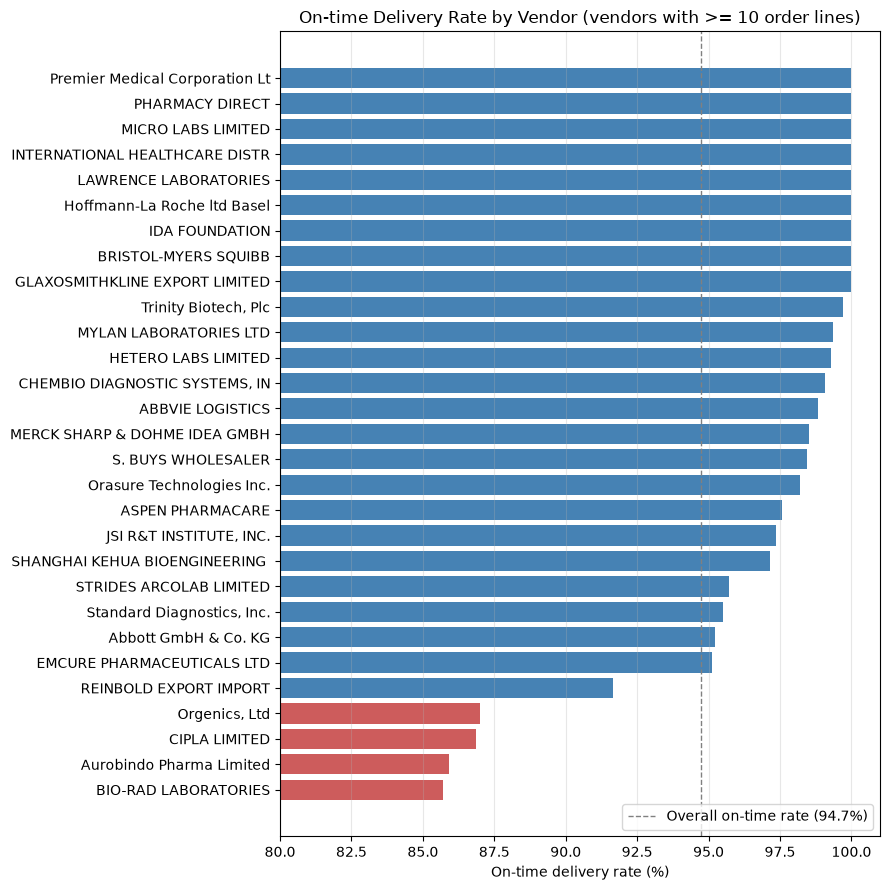

In [15]:
# ===== 准时率排名条形图 =====

plt.style.use("default")   # 白底黑字

# 供应商名字太长，做一个简短版：去掉括号里的内容，最多保留 30 个字符
# split("(") 按左括号切开，.str[0] 取括号前面那段，strip() 去掉空格，.str[:30] 取前 30 个字符
short_names = vendor_delivery.index.str.split("(").str[0].str.strip().str[:30]

# 颜色：准时率低于 90% 的标成红色，其余为蓝色（列表推导式，ABC 项目里用过）
colors = ["indianred" if r < 0.9 else "steelblue" for r in vendor_delivery["OnTimeRate"]]

fig, ax = plt.subplots(figsize=(9, 9))

# barh：横向条形图，供应商名字放在纵轴上更好读
ax.barh(short_names, vendor_delivery["OnTimeRate"] * 100, color=colors)

# 整体准时率的参考线
overall = df_direct["OnTime"].mean() * 100
ax.axvline(overall, color="gray", linestyle="--", linewidth=1,
           label=f"Overall on-time rate ({overall:.1f}%)")

ax.set_xlim(80, 101)        # 横轴从 80% 开始，差异看得更清楚（所有供应商都在 80% 以上）
ax.set_xlabel("On-time delivery rate (%)")
ax.set_title("On-time Delivery Rate by Vendor (vendors with >= 10 order lines)", fontsize=12)
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig("images/ontime_ranking.png", dpi=150)
plt.show()

**交付绩效结论**

- 供应商直接发货订单的记录准时率为 94.7%，经配送中心（RDC）发货的订单约 83%，直接发货更准时
- 迟到订单共 259 行，中位延迟 13 天，平均延迟 25.3 天（被少数严重延迟拉高，最长 192 天）
- 29 家订单行数 ≥ 10 的供应商中，4 家准时率低于 90%：BIO-RAD（85.7%）、Aurobindo（85.9%）、Cipla（86.9%）、Orgenics（87.0%）。其中 3 家是支出前 5 的大供应商，Aurobindo 和 Cipla 迟到时平均延迟 5–6 周
- 批发商 S. BUYS WHOLESALER 平均提前约 29 天到货，体现了批发渠道“以高价换取交付速度”的特点
- 数据局限：86.6% 的直接发货订单实际到货日与计划到货日完全相同，推断计划日期多为事后按实际到货日填写或修改，因此记录准时率很可能高估了真实水平。供应商间的相对比较仍有参考价值，但在评分卡中适当降低交付指标的权重

### 价格—交付综合对比

In [16]:
# ===== 每家供应商的价格指数 =====

# 每一行：如果按保守对标价购买，需要花多少钱
comparable["BenchSpend"] = comparable["ConsBenchmark"] * comparable["Qty"]

# 按供应商汇总：实际花费、按对标价应花费
price_idx = comparable.groupby("Vendor")[["Spend", "BenchSpend"]].sum()
# 价格指数 = 实际花费 ÷ 按对标价应花费
price_idx["PriceIndex"] = price_idx["Spend"] / price_idx["BenchSpend"]

# --- 合并成一张“供应商绩效表” ---
# join：按行标签（供应商名字）把两张表左右拼起来；
# vendor_delivery 和 price_idx 的行标签都是供应商名，所以能一一对上
vendor_perf = vendor_delivery.join(price_idx[["PriceIndex"]], how="inner")

# 再拼上每家供应商的总支出和支出占比
# vendor_spend 的供应商名是普通的一列，先用 set_index 把它变成行标签，才能 join
vendor_perf = vendor_perf.join(vendor_spend.set_index("Vendor")[["TotalSpend", "SpendShare"]])

# how="inner"：只保留两张表里都有的供应商（既有 >= 10 行订单、又参与了价格对标）
print("同时有交付和价格数据的供应商：", len(vendor_perf), "家")
print(f"它们的支出合计占直接采购的：{vendor_perf['SpendShare'].sum():.1%}")

show = vendor_perf[["OrderLines", "OnTimeRate", "PriceIndex", "SpendShare"]].copy()
show["OnTimeRate"] = (show["OnTimeRate"] * 100).round(1)
show["SpendShare"] = (show["SpendShare"] * 100).round(1)
show["PriceIndex"] = show["PriceIndex"].round(2)
print(show.sort_values("SpendShare", ascending=False))

同时有交付和价格数据的供应商： 25 家
它们的支出合计占直接采购的：97.2%
                                                    OrderLines  OnTimeRate  \
Vendor                                                                       
Orgenics, Ltd                                              754        87.0   
Aurobindo Pharma Limited                                   668        85.9   
MYLAN LABORATORIES LTD (FORMERLY MATRIX LABORAT...         317        99.4   
HETERO LABS LIMITED                                        277        99.3   
CIPLA LIMITED                                              175        86.9   
ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV)            347        98.8   
STRIDES ARCOLAB LIMITED                                     93        95.7   
Trinity Biotech, Plc                                       356        99.7   
S. BUYS WHOLESALER                                         715        98.5   
Standard Diagnostics, Inc.                                  89        95.5   
MERCK SHARP & DOHME IDE

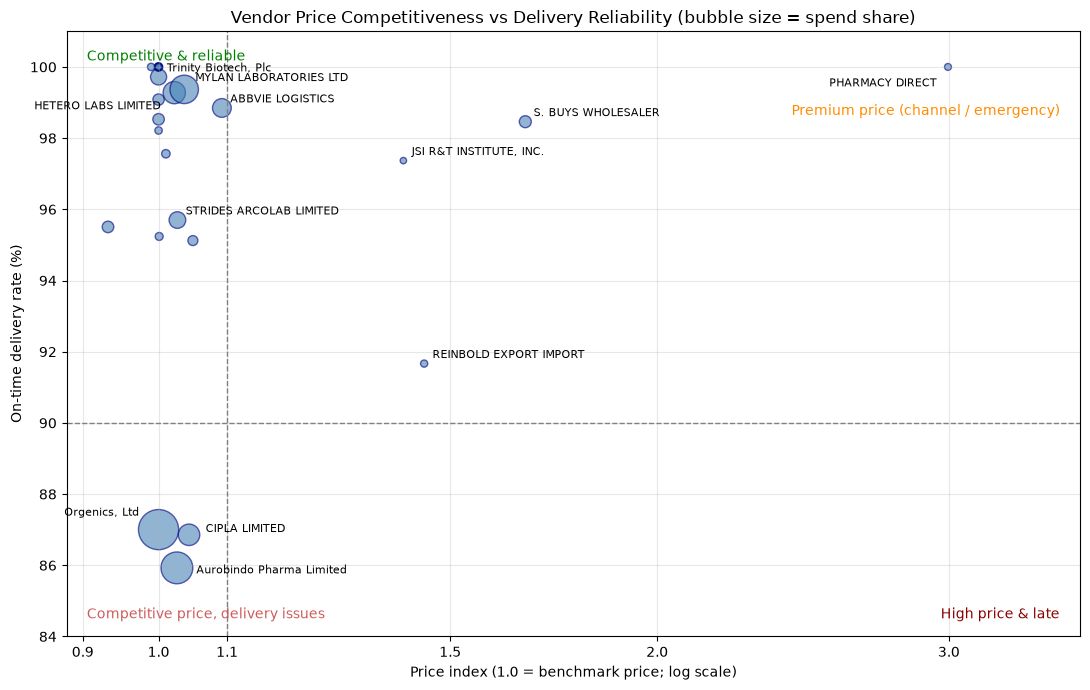

In [17]:
# ===== 价格—准时率四象限散点图 =====

plt.style.use("default")                     # 白底黑字，不受 PyCharm 深色主题影响
fig, ax = plt.subplots(figsize=(11, 7))      # 新建画布，宽 11、高 7 英寸

# --- 1. 画气泡 ---
# 气泡大小：按支出占比放大（乘以 3000 让气泡看得清），再加 20，保证小供应商也看得见
sizes = vendor_perf["SpendShare"] * 3000 + 20

# 散点：横轴是价格指数，纵轴是准时率（乘 100 变成百分数）
# alpha=0.6 是半透明，重叠的气泡也能看见；edgecolor 是气泡的边框颜色
ax.scatter(vendor_perf["PriceIndex"], vendor_perf["OnTimeRate"] * 100,
           s=sizes, color="steelblue", alpha=0.6, edgecolor="navy")

# --- 2. 横轴用对数刻度 ---
# 大部分供应商挤在 0.93~1.09，PHARMACY DIRECT 在 3.00；对数刻度能把左边挤在一起的点分开
ax.set_xscale("log")
ax.set_xticks([0.9, 1.0, 1.1, 1.5, 2.0, 3.0])                       # 在这些位置放刻度
ax.set_xticklabels(["0.9", "1.0", "1.1", "1.5", "2.0", "3.0"])      # 刻度上显示的文字

# --- 3. 两条分界线，把图分成四个象限 ---
ax.axvline(1.10, color="gray", linestyle="--", linewidth=1)   # 竖线：价格指数 1.10（贵 10% 以内算有竞争力）
ax.axhline(90, color="gray", linestyle="--", linewidth=1)     # 横线：准时率 90%

# --- 4. 给重要的供应商标名字 ---
# 容易重叠的供应商，单独指定文字位置：(往右偏多少, 往上偏多少, 文字对齐方式)
# 负数表示往左 / 往下；"right" 表示文字的右端对准这个位置（即文字放在点的左边）
label_pos = {
    "MYLAN LABORATORIES LTD": (8, 6, "left"),
    "HETERO LABS LIMITED": (-10, -12, "right"),
    "Orgenics, Ltd": (-14, 10, "right"),
    "CIPLA LIMITED": (12, 2, "left"),
    "Aurobindo Pharma Limited": (14, -4, "left"),
    "PHARMACY DIRECT": (-8, -14, "right"),
}

# iterrows()：一行一行地取出表格；name 是行标签（供应商名），row 是这一行的数据
for name, row in vendor_perf.iterrows():
    # 只标重要的：支出占比 >= 3%、或价格指数 > 1.3、或准时率 < 90%
    if row["SpendShare"] >= 0.03 or row["PriceIndex"] > 1.3 or row["OnTimeRate"] < 0.9:
        short = name.split("(")[0].strip()[:25]           # 名字缩短：去掉括号部分，最多 25 个字符
        # .get(键, 默认值)：在字典里找这个名字；找不到就用默认位置 (6, 4, "left")
        dx, dy, ha = label_pos.get(short, (6, 4, "left"))
        # annotate：在点 (价格指数, 准时率) 旁边写名字；xytext 是文字相对于点的偏移量
        ax.annotate(short, (row["PriceIndex"], row["OnTimeRate"] * 100),
                    xytext=(dx, dy), textcoords="offset points", fontsize=8, ha=ha)

# --- 5. 四个象限的说明文字（transform=ax.transAxes：按图框比例定位置，0 是左/下边，1 是右/上边）---
ax.text(0.02, 0.97, "Competitive & reliable", transform=ax.transAxes,
        fontsize=10, color="green", va="top")
ax.text(0.98, 0.88, "Premium price (channel / emergency)", transform=ax.transAxes,
        fontsize=10, color="darkorange", va="top", ha="right")      # 往下挪到 0.88，避开 PHARMACY DIRECT
ax.text(0.02, 0.03, "Competitive price, delivery issues", transform=ax.transAxes,
        fontsize=10, color="indianred")
ax.text(0.98, 0.03, "High price & late", transform=ax.transAxes,
        fontsize=10, color="darkred", ha="right")

# --- 6. 标题、坐标轴、范围、网格 ---
ax.set_xlabel("Price index (1.0 = benchmark price; log scale)")
ax.set_ylabel("On-time delivery rate (%)")
ax.set_title("Vendor Price Competitiveness vs Delivery Reliability (bubble size = spend share)", fontsize=12)
ax.set_ylim(84, 101)        # 纵轴范围：所有供应商都在 85% 以上，从 84 开始让差异更明显
ax.set_xlim(0.88, 3.6)      # 横轴右边留出空间，PHARMACY DIRECT 的名字不会被切掉
ax.grid(alpha=0.3)          # 浅色网格线

# --- 7. 保存和显示 ---
plt.tight_layout()                                              # 自动调整边距
plt.savefig("images/price_vs_ontime_quadrant.png", dpi=150)     # 保存图片（会覆盖旧版）
plt.show()

**价格—交付四象限结论**

- 25 家同时具备价格与交付数据的供应商，覆盖直接采购支出的 97.2%。价格指数 = 实际支出 ÷ 按保守对标价应支出（1.0 = 对标价）
- 药厂和品牌商价格指数集中在 0.93–1.09，差异较小；批发、药房和贸易渠道为 1.41–3.00
- 优选（价格有竞争力且准时）：Mylan、Hetero、Trinity Biotech、Strides、Standard Diagnostics 等
- 价格好、交付差：Orgenics、Aurobindo、Cipla 三家合计占直接采购支出的 51.4%，准时率均低于 90%。它们规模大、价格有竞争力，替换难度大，建议通过合同交付条款、提前备货和定期绩效回顾推动交付改进
- 高价准时：S. BUYS、PHARMACY DIRECT 等渠道商以高价换取交付速度，适合作为应急备份而非常规采购来源
- 没有供应商落在“高价且延迟”象限
- 注意：Orgenics 等价格指数为 1.0 的供应商，部分原因是缺少有规模的竞争供应商，其价格本身即为对标价，反映的是竞争性报价不足，而非价格一定最优

## 6. 供应商评分卡

In [18]:
# ===== 6. 供应商评分卡（锚点打分法）=====

# --- 1. 每家供应商的运费占比（只用有运费金额的订单）---
freight_rows = df_direct[df_direct["Freight_Type"] == "Numeric"]     # 只保留运费是数字的行
freight = freight_rows.groupby("Vendor")[["Freight_Num", "Line Item Value"]].sum()
freight["FreightRatio"] = freight["Freight_Num"] / freight["Line Item Value"]   # 运费 ÷ 货款

# --- 2. 拼成评分卡的原始数据表（以四象限图里的 25 家供应商为准）---
scorecard = vendor_perf[["OrderLines", "TotalSpend", "SpendShare", "PriceIndex", "OnTimeRate"]].join(
    freight[["FreightRatio"]])
print("没有运费金额数据的供应商：", scorecard["FreightRatio"].isna().sum(), "家")

# --- 3. 锚点打分：每个指标按“满分线”和“零分线”换算成 0~1 分 ---
# .clip(0, 1)：小于 0 的变成 0，大于 1 的变成 1，保证分数落在 0~1 之间

# 价格：价格指数 1.00 及以下得 1 分，1.50 及以上得 0 分，中间按比例
# 例：1.04 → 1 - (1.04 - 1) / 0.5 = 0.92
scorecard["S_Price"] = (1 - (scorecard["PriceIndex"] - 1.0) / 0.5).clip(0, 1)

# 交付：准时率 100% 得 1 分，80% 及以下得 0 分，中间按比例
# 例：90% → (0.90 - 0.80) / 0.20 = 0.5
scorecard["S_Delivery"] = ((scorecard["OnTimeRate"] - 0.80) / 0.20).clip(0, 1)

# 运费：运费占比 0% 得 1 分，20% 及以上得 0 分，中间按比例
# 例：5% → 1 - 0.05 / 0.20 = 0.75
scorecard["S_Freight"] = (1 - scorecard["FreightRatio"] / 0.20).clip(0, 1)
scorecard["S_Freight"] = scorecard["S_Freight"].fillna(0.5)   # 没有运费数据的供应商给中间分 0.5

# 战略重要性：支出占比 10% 及以上得 1 分，0% 得 0 分，中间按比例
# 例：5% → 0.05 / 0.10 = 0.5
scorecard["S_Spend"] = (scorecard["SpendShare"] / 0.10).clip(0, 1)

# --- 4. 加权求和得到总分 ---
weights = {"S_Price": 0.35, "S_Spend": 0.30, "S_Delivery": 0.20, "S_Freight": 0.15}   # 字典：指标 → 权重

scorecard["TotalScore"] = 0                    # 先建一列，全部是 0
for col, w in weights.items():                 # items()：一次取出字典里的“键”和“值”
    scorecard["TotalScore"] = scorecard["TotalScore"] + scorecard[col] * w   # 每个指标分 × 权重，累加

# --- 5. 按总分从高到低显示 ---
scorecard = scorecard.sort_values("TotalScore", ascending=False)

show = scorecard.copy()
show.index = show.index.str.split("(").str[0].str.strip().str[:25]   # 名字缩短，表格好读
show["SpendShare"] = (show["SpendShare"] * 100).round(1)             # 单位：%
show["OnTimeRate"] = (show["OnTimeRate"] * 100).round(1)             # 单位：%
show["FreightRatio"] = (show["FreightRatio"] * 100).round(1)         # 单位：%
show = show.round({"PriceIndex": 2, "S_Price": 2, "S_Spend": 2, "S_Delivery": 2,
                   "S_Freight": 2, "TotalScore": 3})
print(show[["SpendShare", "PriceIndex", "OnTimeRate", "FreightRatio",
            "S_Price", "S_Spend", "S_Delivery", "S_Freight", "TotalScore"]])

没有运费金额数据的供应商： 3 家
                           SpendShare  PriceIndex  OnTimeRate  FreightRatio  \
Vendor                                                                        
MYLAN LABORATORIES LTD           13.3        1.04        99.4           4.9   
HETERO LABS LIMITED               7.9        1.02        99.3           8.3   
Orgenics, Ltd                    27.2        1.00        87.0           7.1   
Aurobindo Pharma Limited         16.9        1.03        85.9           6.2   
ABBVIE LOGISTICS                  5.4        1.09        98.8           7.6   
MERCK SHARP & DOHME IDEA          1.6        1.00        98.5           0.9   
Trinity Biotech, Plc              3.8        1.00        99.7          11.7   
STRIDES ARCOLAB LIMITED           4.1        1.03        95.7           5.2   
CIPLA LIMITED                     7.3        1.04        86.9           5.2   
INTERNATIONAL HEALTHCARE          0.1        1.00       100.0           0.3   
GLAXOSMITHKLINE EXPORT LI         

In [19]:
# ===== 供应商分级 =====

# 定义分级规则的函数：输入总分，返回等级（和 ABC 项目里的 abc_class 是同一种写法）
def vendor_tier(score):
    if score >= 0.75:
        return "Strategic"     # 战略
    elif score >= 0.65:
        return "Preferred"     # 优先
    elif score >= 0.50:
        return "Approved"      # 一般
    else:
        return "Watch"         # 观察

# apply：把函数套用到总分列的每一个值上，结果存进新列 Tier
scorecard["Tier"] = scorecard["TotalScore"].apply(vendor_tier)

# 交付红线：准时率低于 90% 的，不论等级都标记“交付需改进”
scorecard["DeliveryFlag"] = scorecard["OnTimeRate"] < 0.90

# --- 各等级的供应商数量和支出占比 ---
tier_summary = scorecard.groupby("Tier").agg(
    Vendors=("TotalScore", "count"),     # 每个等级有几家供应商
    SpendShare=("SpendShare", "sum")     # 每个等级的支出占直接采购的比例
)
# reindex：按指定的顺序重新排列行（默认会按字母排，变成 Approved、Preferred……）
tier_summary = tier_summary.reindex(["Strategic", "Preferred", "Approved", "Watch"])
tier_summary["SpendShare"] = (tier_summary["SpendShare"] * 100).round(1)   # 单位：%
print("各等级供应商数量和支出占比（%）：")
print(tier_summary)

# --- 被标记“交付需改进”的供应商 ---
print("\n交付需改进（准时率 < 90%）：")
print(scorecard[scorecard["DeliveryFlag"]][["Tier", "OnTimeRate"]])

# --- 保存评分卡 CSV ---
out = scorecard.copy()
out = out.round({"SpendShare": 4, "PriceIndex": 3, "OnTimeRate": 3, "FreightRatio": 3,
                 "S_Price": 2, "S_Spend": 2, "S_Delivery": 2, "S_Freight": 2, "TotalScore": 3})
# index_label：保存时把行标签（供应商名）这一列命名为 Vendor
out.to_csv("data/vendor_scorecard.csv", index_label="Vendor")
print("\n供应商评分卡已保存，共", len(out), "家供应商")

各等级供应商数量和支出占比（%）：
           Vendors  SpendShare
Tier                          
Strategic        4        65.3
Preferred       11        25.8
Approved         6         3.8
Watch            4         2.3

交付需改进（准时率 < 90%）：
                               Tier  OnTimeRate
Vendor                                         
Orgenics, Ltd             Strategic    0.870027
Aurobindo Pharma Limited  Strategic    0.859281
CIPLA LIMITED             Preferred    0.868571

供应商评分卡已保存，共 25 家供应商


**评分卡方法**

- 指标与权重：价格竞争力 35%、战略重要性（支出占比）30%、交付准时率 20%、运费占比 15%
- 权重理由：价格指数基于保守对标，数据可靠，权重最高；分级的目的是分配管理资源，支出规模直接决定供应商对业务的影响；准时率疑似被高估（86.6% 的订单到货日与计划日完全相同），适当降低权重；运费仅约 60% 的订单有金额，且受贸易条款和运输方式影响，权重最低
- 归一化：最初采用排名百分位，发现它会放大微小差异（价格指数 1.00 与 1.04 分差达 0.40）、忽略极端差距（1.67 与 3.00 仅差 0.04），因此改为锚点打分。价格指数 ≤ 1.00 得满分、≥ 1.50 得 0 分；准时率 100% 满分、≤ 80% 为 0；运费占比 0% 满分、≥ 20% 为 0；支出占比 ≥ 10% 满分；中间按线性比例给分
- 分级：总分 ≥ 0.75 为战略，0.65–0.75 为优先，0.50–0.65 为一般，< 0.50 为观察（分界线参考了总分分布中的自然断层）。另设交付红线：准时率 < 90% 的供应商不论等级均标记为“交付需改进”

**分级结果与管理建议**

| 等级 | 供应商数 | 支出占比 | 管理建议 |
|---|---|---|---|
| 战略 | 4 | 65.3% | 签订长期框架协议，联合需求预测，季度业务回顾；Orgenics 和 Aurobindo 设定交付 KPI 与安全库存要求；Orgenics 一家占 27%，应培育第二供货来源，降低单一依赖 |
| 优先 | 11 | 25.8% | 稳定合作，作为战略供应商的替代来源，可适度提升份额（如由 Strides、Hetero 分担部分同类药品）；Cipla 需推动交付改进 |
| 一般 | 6 | 3.8% | 常规管理，年度评估；Standard Diagnostics、Micro Labs、Lawrence 运费占比 13%–17%，可通过合并发运、调整运输方式或贸易条款降低到岸成本 |
| 观察 | 4 | 2.3% | 批发与贸易渠道，价格高出 40%–200%，仅限应急使用并设审批门槛；通过改进需求计划减少紧急采购（保守估计节约约 $390 万） |

## 7. 结论

**主要发现**

1. **支出高度集中**：直接采购 5.42 亿美元、72 家供应商，CR4 为 65.3%，7 家供应商（9.7%）贡献 80% 的支出
2. **价差普遍存在**：在同年同规格可比的 75 个商品中，54 个存在 20% 以上的供应商价差；潜在议价空间保守估计约 1,323 万美元（可比支出的 3.5%），理论上限约 2,610 万美元
3. **最可靠的节约来自渠道而非压价**：批发和药房渠道按供应商整体计算的价格指数为 1.4–3.0（即比对标价贵 40%–200%），减少紧急采购比重新谈判合同更确定
4. **核心供应商交付不稳**：准时率低于 90% 的 3 家供应商（Orgenics、Aurobindo、Cipla）合计占直接采购支出的 51.4%
5. **供应商分级**：战略 4 家、优先 11 家、一般 6 家、观察 4 家

**局限性**

- 52% 的订单经配送中心发货，无法识别上游供应商，供应商分析仅覆盖直接采购部分（总支出的 33.3%）
- 86.6% 的订单到货日与计划日完全一致，准时率很可能被高估
- 潜在节约为理论估算，未考虑产能、药品注册、交货期、合同条款等现实约束
- 原研药厂和占绝对份额的供应商缺少有规模的竞争对手，价格指数为 1.0 反映的是缺乏竞争，而非价格最优
- 数据跨度 2006–2015 年，为历史公共卫生采购数据，结论用于方法展示